# 03 — Phân cụm khách hàng: K-Means và GMM/DBSCAN

**Phần A — K-Means: ChinhBui · 06/11/2026**

Mục 2.3: chọn K bằng Elbow và Silhouette, đánh giá định lượng, mô tả khách hàng, tỷ lệ Response trong từng cụm; hình tô màu theo cụm và hình dạng theo nhãn.

Thực nghiệm chính dùng train 80:20 trong development, so sánh không giảm chiều và PCA còn 1/3 số chiều. Chạy thêm 70:30 và 60:40 để khảo sát độ nhạy với tập train. Mỗi lần fit preprocessing/PCA/K-Means riêng trên train. Validation chỉ transform và gán về tâm gần nhất; mọi lựa chọn K dùng **X train**, không dùng Response hay điểm validation. Test cuối được giữ riêng.

Phần B dành cho GMM/DBSCAN của Tuananh; phần C so sánh chung sẽ hoàn thiện sau.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/clustering.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import config, preprocessing, data_splitting
from src.clustering import analyze_kmeans, describe_clusters, initialization_stability

config.ensure_dirs()
FIGURES, TABLES = config.FIGURES_CLUSTERING_DIR, config.TABLES_DIR
OUTPUT = config.PROCESSED_DATA_DIR / 'clustering'
OUTPUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 25)

def snapshot():
    return {p.name: (hashlib.sha256(p.read_bytes()).hexdigest(), p.stat().st_mtime_ns)
            for p in config.SPLITS_DIR.iterdir() if p.is_file()}

assert (config.SPLITS_DIR / 'manifest.json').exists(), 'Chạy notebook 01 trước.'
frozen_before = snapshot()
manifest = data_splitting.export_splits(preprocessing.load_raw())
assert snapshot() == frozen_before
assignments = pd.read_csv(config.SPLITS_DIR / 'assignments.csv', dtype={'duplicate_group': str})
development = pd.read_csv(config.SPLITS_DIR / 'development.csv')
is_development = assignments.partition.eq('development')
test_groups = set(assignments.loc[~is_development, 'duplicate_group'])

def save_figure(name):
    plt.gcf().savefig(FIGURES / f'{name}.png', dpi=config.FIGURE_DPI, bbox_inches='tight')
    plt.show()
    plt.close()

print('Train-only, seed:', config.RANDOM_SEED, '| K candidates:', config.KMEANS_CANDIDATE_K)
print('Test không được đưa vào fit, gán cụm hoặc biểu đồ.')

Train-only, seed: 42 | K candidates: (2, 3, 4, 5, 6, 7, 8, 9, 10)
Test không được đưa vào fit, gán cụm hoặc biểu đồ.


## A1. Không gian phân cụm và cách chọn K

- **Không PCA:** median + StandardScaler cho cột số; most frequent + one-hot cho category, hiện 37 chiều. Cột nhị phân dạng số cũng được chuẩn hóa theo pipeline đã chốt.
- **PCA 1/3:** cùng tiền xử lý, PCA fit train còn 12 chiều. K-Means chạy trong 12 chiều này, không chỉ hai trục để vẽ.
- Thử K = 2…10, mỗi K dùng `n_init=10`, seed 42. Chọn **Silhouette train lớn nhất**, hòa thì K nhỏ hơn. Elbow cung cấp gợi ý bổ sung: khoảng cách lớn nhất dưới dây nối hai đầu đường inertia đã chuẩn hóa. Đây là heuristic, không bảo đảm có một K đúng duy nhất.
- Nếu Elbow và Silhouette khác nhau, giữ quy tắc đã định trước và giải thích khác biệt. Không dùng tỷ lệ Response để chọn K. Các chỉ số nội tại không chứng minh cụm có giá trị kinh doanh hay dự đoán được nhãn.
- K-Means dùng khoảng cách Euclid, ưu tiên các cụm tương đối tròn. Biến tổng và các thành phần tương quan có thể làm một nhóm hành vi được tính nhiều lần; one-hot và chuẩn hóa biến nhị phân cũng ảnh hưởng khoảng cách.

In [2]:
experiments, evaluations, selection_rows, stability_rows = {}, [], [], []
for split, folds in [('80_20', 2), ('70_30', 3), ('60_40', 4)]:
    train = pd.read_csv(config.SPLITS_DIR / f'train_{split}.csv')
    validation = pd.read_csv(config.SPLITS_DIR / f'validation_{split}.csv')
    train_meta = assignments.loc[is_development & assignments.development_fold.ge(folds)].reset_index(drop=True)
    val_meta = assignments.loc[is_development & assignments.development_fold.lt(folds)].reset_index(drop=True)
    dev_folds = assignments.loc[is_development, 'development_fold'].reset_index(drop=True)
    pd.testing.assert_frame_equal(train, development.loc[dev_folds.ge(folds)].reset_index(drop=True))
    pd.testing.assert_frame_equal(validation, development.loc[dev_folds.lt(folds)].reset_index(drop=True))
    train_groups, val_groups = set(train_meta.duplicate_group), set(val_meta.duplicate_group)
    assert train_groups.isdisjoint(val_groups)
    assert (train_groups | val_groups).isdisjoint(test_groups)
    for space, reduced in [('encoded', False), ('pca', True)]:
        name = f'{split}_{space}'
        with threadpool_limits(limits=2):
            result = analyze_kmeans(train.drop(columns='Response'), validation.drop(columns='Response'), reduce=reduced)
            stability = initialization_stability(result['train_space'], result['train_labels'], result['selected_k'])
        result.update(train=train, validation=validation, train_metadata=train_meta, validation_metadata=val_meta)
        experiments[name] = result
        candidates = result['candidates'].assign(split=split, space=space)
        candidates.to_csv(TABLES / f'kmeans_{name}_k_selection.csv', index=False)
        evaluation = result['evaluation'].assign(split=split, space=space)
        evaluations.append(evaluation)
        stability_rows.append(stability.assign(split=split, space=space))
        selection_rows.append({'split': split, 'space': space, 'dimensions': result['train_space'].shape[1],
                               'selected_k': result['selected_k'], 'elbow_suggestion_k': result['elbow_k'],
                               'train_silhouette': evaluation.iloc[0].silhouette,
                               'validation_silhouette': evaluation.iloc[1].silhouette,
                               'minimum_seed_ari': stability.ari_vs_reference.min()})
        print(name, 'selected K:', result['selected_k'], '| elbow suggestion:', result['elbow_k'])
selection = pd.DataFrame(selection_rows)
evaluation_table = pd.concat(evaluations, ignore_index=True)
stability_table = pd.concat(stability_rows, ignore_index=True)
selection.to_csv(TABLES / 'kmeans_selection_summary.csv', index=False)
evaluation_table.to_csv(TABLES / 'kmeans_evaluation.csv', index=False)
stability_table.to_csv(TABLES / 'kmeans_initialization_stability.csv', index=False)
display(selection)
display(evaluation_table)

80_20_encoded selected K: 2 | elbow suggestion: 5


80_20_pca selected K: 2 | elbow suggestion: 5


70_30_encoded selected K: 2 | elbow suggestion: 5


70_30_pca selected K: 2 | elbow suggestion: 5


60_40_encoded selected K: 2 | elbow suggestion: 5


60_40_pca selected K: 2 | elbow suggestion: 5


,split,space,dimensions,selected_k,elbow_suggestion_k,train_silhouette,validation_silhouette,minimum_seed_ari
0,80_20,encoded,37,2,5,0.265792,0.275071,0.994393
1,80_20,pca,12,2,5,0.311775,0.322626,1.000000
2,70_30,encoded,37,2,5,0.267207,0.270077,1.000000
3,70_30,pca,12,2,5,0.312975,0.320253,1.000000
4,60_40,encoded,37,2,5,0.272354,0.259727,1.000000
5,60_40,pca,12,2,5,0.318796,0.309274,1.000000


,partition,selected_k,mean_squared_distance_to_centroid,rows,clusters_present,silhouette,davies_bouldin,calinski_harabasz,split,space
0,train,2,22.887018,1430,2,0.265792,1.677175,451.482437,80_20,encoded
1,validation,2,22.203353,358,2,0.275071,1.592127,123.359478,80_20,encoded
2,train,2,16.918085,1430,2,0.311775,1.411508,610.380056,80_20,pca
3,validation,2,16.274259,358,2,0.322626,1.344337,165.532360,80_20,pca
4,train,2,22.919614,1250,2,0.267207,1.678117,392.801933,70_30,encoded
5,validation,2,22.749859,538,2,0.270077,1.603286,188.528616,70_30,encoded
6,train,2,16.957084,1250,2,0.312975,1.415499,530.620109,70_30,pca
7,validation,2,16.406480,538,2,0.320253,1.339250,260.804618,70_30,pca
8,train,2,22.820485,1072,2,0.272354,1.662792,343.026196,60_40,encoded
9,validation,2,23.238249,716,2,0.259727,1.658215,234.456293,60_40,encoded


In [3]:
agreement = []
for split in ['80_20', '70_30', '60_40']:
    original, reduced = experiments[f'{split}_encoded'], experiments[f'{split}_pca']
    for role in ['train', 'validation']:
        agreement.append({'split': split, 'partition': role,
                          'ari_encoded_vs_pca': adjusted_rand_score(original[f'{role}_labels'], reduced[f'{role}_labels'])})
agreement = pd.DataFrame(agreement)
agreement.to_csv(TABLES / 'kmeans_representation_agreement.csv', index=False)
display(agreement)
print('ARI so phân hoạch trên cùng mẫu, không phụ thuộc hoán vị ID cụm; không phải độ chính xác theo Response.')

,split,partition,ari_encoded_vs_pca
0,80_20,train,1.000000
1,80_20,validation,0.977634
2,70_30,train,0.990383
3,70_30,validation,0.992553
4,60_40,train,0.992513
5,60_40,validation,1.000000


ARI so phân hoạch trên cùng mẫu, không phụ thuộc hoán vị ID cụm; không phải độ chính xác theo Response.


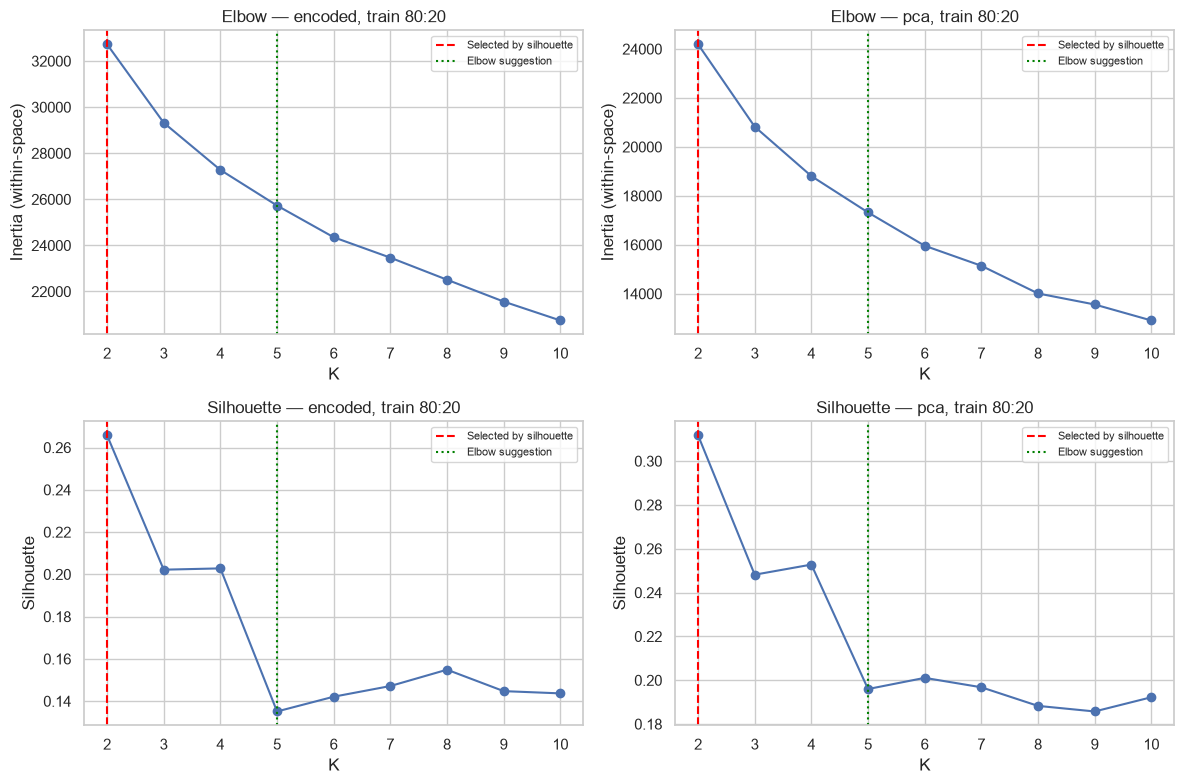

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, space in enumerate(['encoded', 'pca']):
    result = experiments[f'80_20_{space}']
    scores = result['candidates']
    axes[0, column].plot(scores.k, scores.inertia, marker='o')
    axes[0, column].set(title=f'Elbow — {space}, train 80:20', ylabel='Inertia (within-space)', xlabel='K')
    axes[1, column].plot(scores.k, scores.silhouette, marker='o')
    axes[1, column].set(title=f'Silhouette — {space}, train 80:20', ylabel='Silhouette', xlabel='K')
    for row in [0, 1]:
        axes[row, column].axvline(result['selected_k'], ls='--', color='red', label='Selected by silhouette')
        if result['elbow_k'] is not None:
            axes[row, column].axvline(result['elbow_k'], ls=':', color='green', label='Elbow suggestion')
        axes[row, column].set_xticks(scores.k)
        axes[row, column].legend(fontsize=8)
plt.tight_layout()
save_figure('kmeans_80_20_elbow_silhouette')

## A2. Đánh giá cụm và tính ổn định

Silhouette càng cao càng tốt (−1 đến 1); Davies–Bouldin càng thấp càng tốt; Calinski–Harabasz càng cao càng tốt trong cùng điều kiện. Validation được gán bằng tâm đã học trên train. Nếu validation chỉ có một cụm, các điểm nội tại không xác định được và báo NaN.

Không so trực tiếp inertia giữa 37 chiều và 12 chiều như cùng một thước đo. Silhouette của hai không gian cũng phụ thuộc phép biểu diễn; cao hơn sau PCA chưa đủ chứng minh phân nhóm hữu ích hơn. Các tập train/validation có kích thước khác nhau nên điểm không hoàn toàn tương đương.

ARI so nhãn cụm khi đổi seed với lần seed 42, không so với Response. ARI = 1 thể hiện phân hoạch giống nhau dù ID cụm đổi. Đây chỉ là độ ổn định khi khởi tạo trên cùng train, không chứng minh ổn định khi thay tập khách hàng.

,seed,inertia,ari_vs_reference,split,space
0,7,32728.435652,1.000000,80_20,encoded
1,21,32728.499763,0.994394,80_20,encoded
2,42,32728.435652,1.000000,80_20,encoded
3,84,32728.587666,0.994393,80_20,encoded
4,123,32728.587666,0.994393,80_20,encoded
5,7,24192.861716,1.000000,80_20,pca
6,21,24192.861716,1.000000,80_20,pca
7,42,24192.861716,1.000000,80_20,pca
8,84,24192.861716,1.000000,80_20,pca
9,123,24192.861716,1.000000,80_20,pca


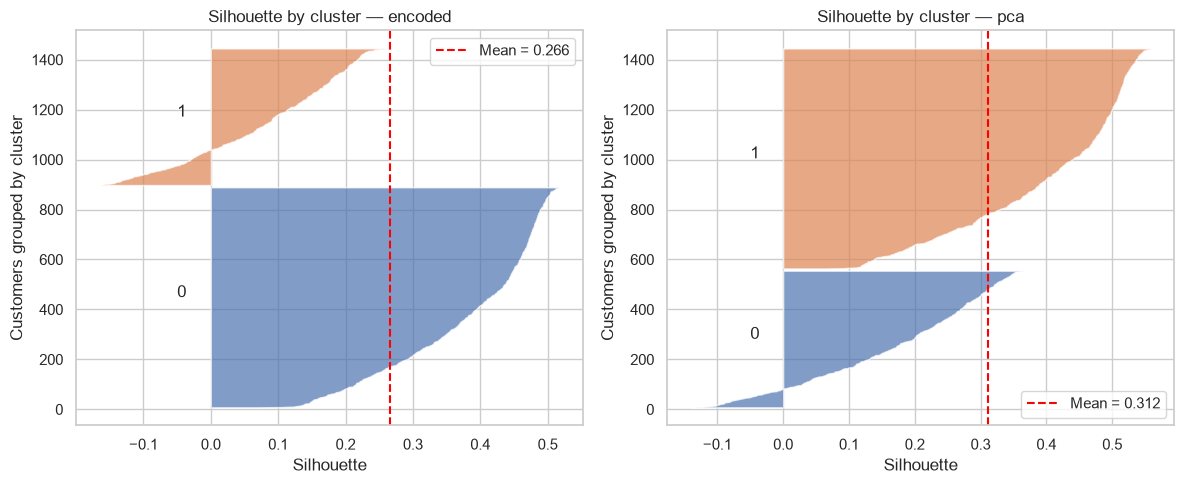

In [5]:
display(stability_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for space, ax in zip(['encoded', 'pca'], axes):
    result = experiments[f'80_20_{space}']
    with threadpool_limits(limits=2):
        values = silhouette_samples(result['train_space'], result['train_labels'])
    lower = 8
    for cluster in range(result['selected_k']):
        part = np.sort(values[result['train_labels'] == cluster])
        upper = lower + len(part)
        ax.fill_betweenx(np.arange(lower, upper), 0, part, alpha=.7)
        ax.text(-.05, (lower + upper) / 2, str(cluster))
        lower = upper + 8
    ax.axvline(values.mean(), color='red', ls='--', label=f'Mean = {values.mean():.3f}')
    ax.set(title=f'Silhouette by cluster — {space}', xlabel='Silhouette', ylabel='Customers grouped by cluster')
    ax.legend()
plt.tight_layout()
save_figure('kmeans_80_20_cluster_silhouettes')

## A3. Hồ sơ khách hàng và tỷ lệ hưởng ứng

Thống kê theo đơn vị gốc của các đặc trưng sạch (trước impute/scale/PCA); median bỏ qua giá trị thiếu nên xem cùng bảng thiếu. `response_lift` là tỷ lệ Response=1 của cụm chia tỷ lệ lớp 1 của toàn bộ phân vùng tương ứng. Đây là thống kê mô tả sau phân cụm, không phải xác suất đã hiệu chuẩn hoặc nhãn dự đoán.

ID cụm là quy ước của từng mô hình. Không coi “cụm 0” ở các tập chia/không gian khác nhau là cùng nhóm khách hàng. Kết quả train và validation của cùng mô hình dùng chung tâm nên cùng hệ ID.

In [6]:
profile_rows = []
for name, result in experiments.items():
    directory = OUTPUT / name
    directory.mkdir(parents=True, exist_ok=True)
    for partition in ['train', 'validation']:
        data = result[partition]
        labels = result[f'{partition}_labels']
        profile = describe_clusters(data.drop(columns='Response'), data.Response, labels)
        result[f'{partition}_profile'] = profile
        for kind, table in profile.items():
            table.to_csv(TABLES / f'kmeans_{name}_{partition}_{kind}.csv', index=(kind != 'categories'))
        missing = data.drop(columns='Response').assign(cluster=labels).groupby('cluster').agg(lambda col: col.isna().sum())
        missing.to_csv(TABLES / f'kmeans_{name}_{partition}_missing.csv')
        profile_rows.append(profile['summary'].reset_index().assign(experiment=name, partition=partition))
        row_labels = result[f'{partition}_metadata'].copy()
        row_labels['cluster'] = labels
        row_labels['Response'] = data.Response.to_numpy()
        row_labels.to_csv(directory / f'{partition}_cluster_assignments.csv', index=False)
    joblib.dump(result['pipeline'], directory / 'kmeans_pipeline.joblib')
    restored = joblib.load(directory / 'kmeans_pipeline.joblib')
    np.testing.assert_array_equal(restored.predict(result['validation'].drop(columns='Response')), result['validation_labels'])
profile_summary = pd.concat(profile_rows, ignore_index=True)
profile_summary.to_csv(TABLES / 'kmeans_cluster_profiles.csv', index=False)
for space in ['encoded', 'pca']:
    result = experiments[f'80_20_{space}']
    print('Customer profiles:', space)
    display(result['train_profile']['summary'])
    display(result['train_profile']['numeric_median'])
    display(result['validation_profile']['summary'])

Customer profiles: encoded


,rows,response_1,response_rate,fraction,response_lift
cluster,,,,,
0,882,85,0.096372,0.616783,0.647004
1,548,128,0.233577,0.383217,1.568144


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,...,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Age,Customer_Tenure_Days,Total_Spent,Total_Purchases,Total_Accepted_Cmp,Children,Is_Parent,Family_Size
cluster,,,,,,,,,,,,,,,,,,,,,,,,,
0,38774.5,1.0,1.0,51.0,38.0,3.0,22.0,4.0,3.0,14.0,2.0,3.0,...,0.0,0.0,0.0,0.0,42.0,333.5,97.5,6.0,0.0,1.0,1.0,3.0
1,71613.0,0.0,0.0,51.0,549.0,40.0,309.0,65.0,41.5,56.0,1.0,5.0,...,0.0,0.0,0.0,0.0,46.0,403.5,1170.5,20.0,0.0,0.0,0.0,2.0


,rows,response_1,response_rate,fraction,response_lift
cluster,,,,,
0,224,20,0.089286,0.625698,0.591931
1,134,34,0.253731,0.374302,1.682145


Customer profiles: pca


,rows,response_1,response_rate,fraction,response_lift
cluster,,,,,
0,548,128,0.233577,0.383217,1.568144
1,882,85,0.096372,0.616783,0.647004


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,...,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Age,Customer_Tenure_Days,Total_Spent,Total_Purchases,Total_Accepted_Cmp,Children,Is_Parent,Family_Size
cluster,,,,,,,,,,,,,,,,,,,,,,,,,
0,71613.0,0.0,0.0,51.0,549.0,40.0,309.0,65.0,41.5,56.0,1.0,5.0,...,0.0,0.0,0.0,0.0,46.0,403.5,1170.5,20.0,0.0,0.0,0.0,2.0
1,38774.5,1.0,1.0,51.0,38.0,3.0,22.0,4.0,3.0,14.0,2.0,3.0,...,0.0,0.0,0.0,0.0,42.0,333.5,97.5,6.0,0.0,1.0,1.0,3.0


,rows,response_1,response_rate,fraction,response_lift
cluster,,,,,
0,134,34,0.253731,0.374302,1.682145
1,224,20,0.089286,0.625698,0.591931


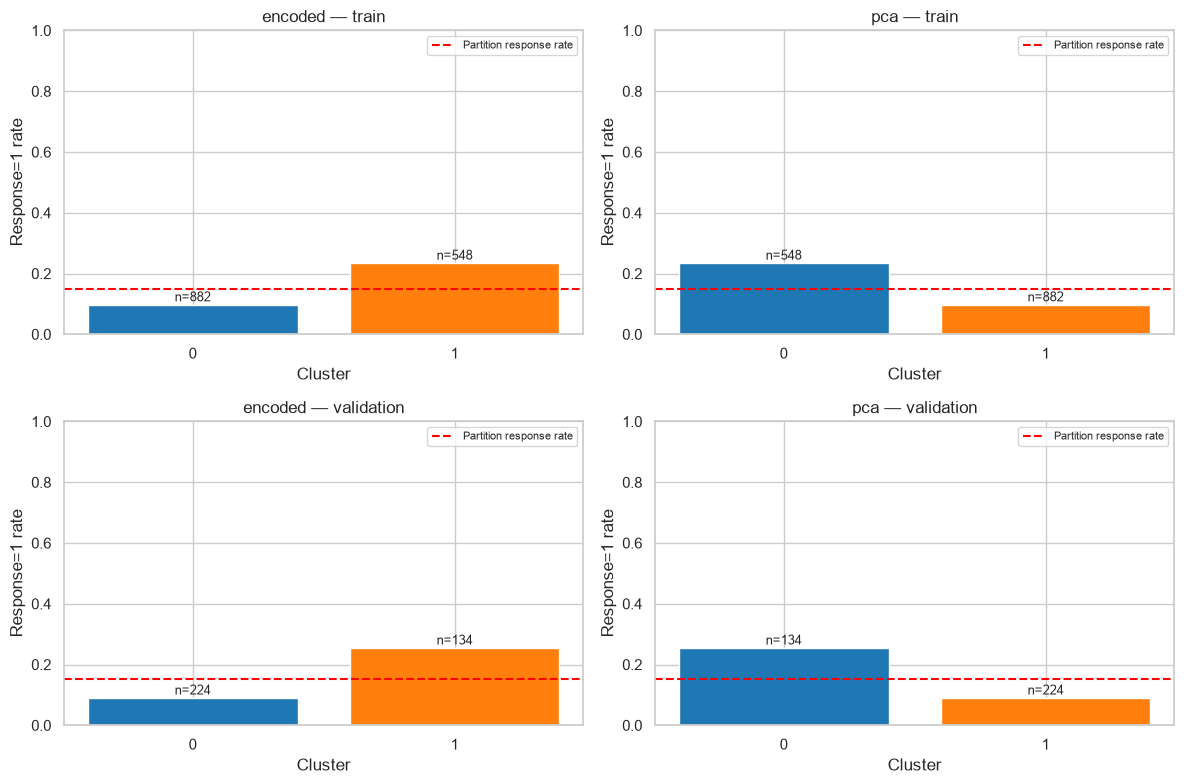

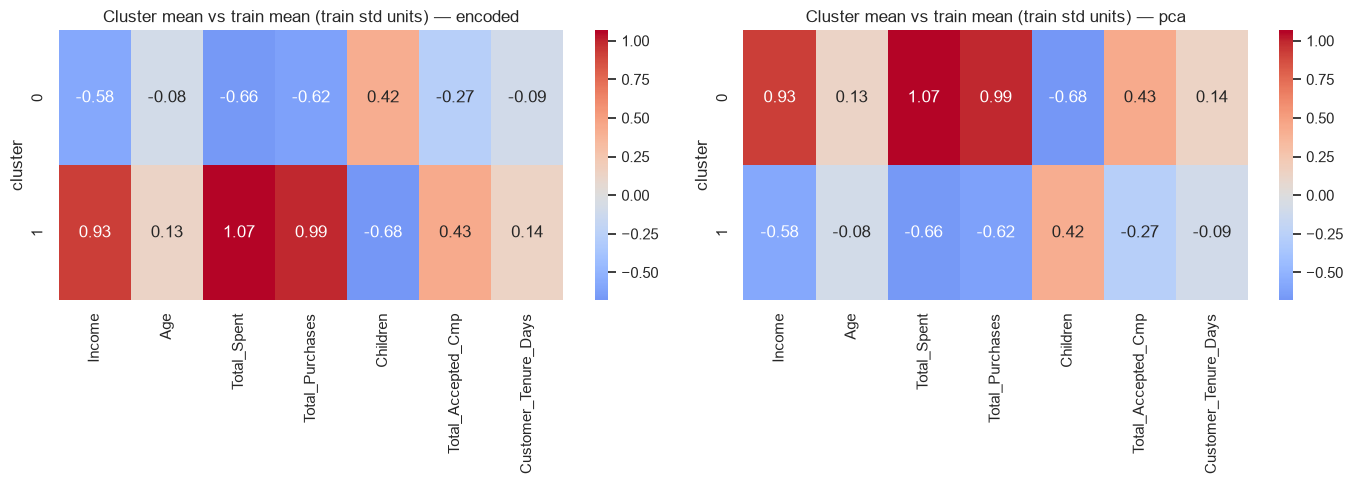

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, space in enumerate(['encoded', 'pca']):
    result = experiments[f'80_20_{space}']
    for row, partition in enumerate(['train', 'validation']):
        table = result[f'{partition}_profile']['summary']
        ax = axes[row, column]
        ax.bar(table.index.astype(str), table.response_rate, color=sns.color_palette('tab10', len(table)))
        ax.axhline(result[partition].Response.mean(), color='red', ls='--', label='Partition response rate')
        for i, (_, entry) in enumerate(table.iterrows()):
            ax.text(i, entry.response_rate + .012, f"n={int(entry.rows)}", ha='center', fontsize=9)
        ax.set(title=f'{space} — {partition}', xlabel='Cluster', ylabel='Response=1 rate', ylim=(0, 1))
        ax.legend(fontsize=8)
plt.tight_layout()
save_figure('kmeans_80_20_response_rates')

features = ['Income', 'Age', 'Total_Spent', 'Total_Purchases', 'Children', 'Total_Accepted_Cmp', 'Customer_Tenure_Days']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, space in zip(axes, ['encoded', 'pca']):
    result = experiments[f'80_20_{space}']
    clean = result['train'][features]
    means = result['train_profile']['numeric_mean'][features]
    standardized_difference = (means - clean.mean()) / clean.std(ddof=1).replace(0, np.nan)
    sns.heatmap(standardized_difference, cmap='coolwarm', center=0, annot=True, fmt='.2f', ax=ax)
    ax.set_title(f'Cluster mean vs train mean (train std units) — {space}')
plt.tight_layout()
save_figure('kmeans_80_20_customer_profiles')

## A4. Màu theo cụm, hình dạng theo Response

Hai panel mỗi không gian thể hiện train và validation. Bản không giảm chiều được **chiếu để vẽ** bằng PCA(2) chỉ fit train, không thay đổi kết quả K-Means 37 chiều. Bản PCA dùng PC1–PC2 từ chính PCA 12 chiều. Hình 2D có thể làm mất khoảng cách và tạo chồng lấn dù điểm nội tại ở không gian đầy đủ khác; không dùng hình này để thay đổi K.

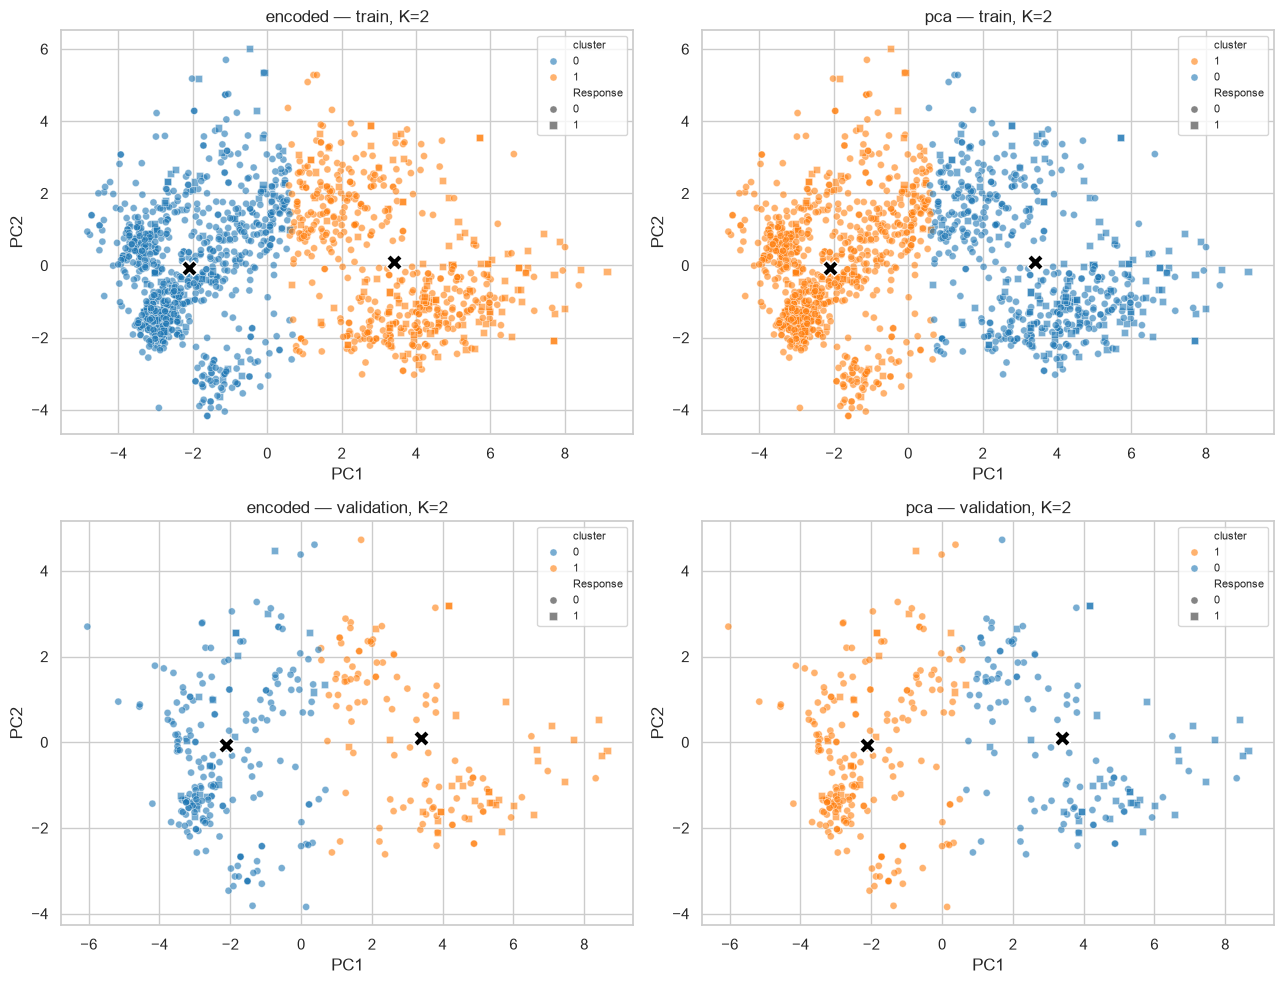

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for column, space in enumerate(['encoded', 'pca']):
    result = experiments[f'80_20_{space}']
    if space == 'encoded':
        projection = PCA(n_components=2, svd_solver='full').fit(result['train_space'])
        coordinates = {role: projection.transform(result[f'{role}_space']) for role in ['train', 'validation']}
        centers = projection.transform(result['model'].cluster_centers_)
    else:
        coordinates = {role: result[f'{role}_space'][:, :2] for role in ['train', 'validation']}
        centers = result['model'].cluster_centers_[:, :2]
    palette = dict(zip([str(i) for i in range(result['selected_k'])], sns.color_palette('tab10', result['selected_k'])))
    for row, role in enumerate(['train', 'validation']):
        ax = axes[row, column]
        plot = pd.DataFrame(coordinates[role], columns=['PC1', 'PC2'])
        plot['cluster'] = result[f'{role}_labels'].astype(str)
        plot['Response'] = result[role].Response.astype(str).to_numpy()
        sns.scatterplot(data=plot, x='PC1', y='PC2', hue='cluster', style='Response',
                        palette=palette, markers={'0': 'o', '1': 's'}, alpha=.6, s=26, ax=ax)
        ax.scatter(centers[:, 0], centers[:, 1], marker='X', s=130, color='black', edgecolor='white')
        ax.set_title(f'{space} — {role}, K={result["selected_k"]}')
        ax.legend(fontsize=8)
plt.tight_layout()
save_figure('kmeans_80_20_clusters_response')

## A5. Kết luận và cách bàn giao

Nhận xét cụ thể từ kết quả chạy nằm ở `docs/kmeans_handoff.md` và được bổ sung bên dưới. Các cụm là phân nhóm hành vi, chưa phải lớp “hưởng ứng/không hưởng ứng”. Độ đo phân loại và kiểm định lợi ích marketing cần bước riêng.

- Bộ hàm: `src/clustering.py`. `analyze_kmeans` chỉ nhận X, trả pipeline đã fit, tâm, nhãn, điểm theo K và điểm train/validation. `describe_clusters` nhận nhãn Response sau khi cụm đã chốt để mô tả.
- Model và nhãn từng khách hàng được lưu cục bộ tại `data/processed/clustering/<tỷ_lệ>_<không_gian>/`, được Git bỏ qua. Model `.predict(X_sạch)` áp dụng tiền xử lý đã fit và gán cụm.
- Tuananh dùng cùng tập chia và cùng cách biểu diễn khi so GMM/DBSCAN. Nếu muốn dùng cụm làm đặc trưng phân loại, phải fit lại preprocessing/PCA/K-Means trong từng fold train; không lấy nhãn cụm fit trên toàn development làm đầu vào trước CV.

### Nhận xét từ dữ liệu thực

- **Chọn K=2 trong cả sáu kịch bản theo Silhouette.** Elbow gợi ý K=5 do inertia giảm đều với mức giảm dần, không có góc gãy duy nhất thật rõ. Ở train 80:20 không PCA, K=2 có Silhouette 0,266, K=4 là 0,203 và K=5 là 0,135. Quy tắc Silhouette ưu tiên hai nhóm lớn; K=5 có thể phân chia chi tiết hơn nhưng độ tách/độ chặt trung bình kém hơn theo tiêu chí này. K=2 không phải khẳng định khách hàng chỉ có hai nhóm kinh doanh đúng duy nhất.
- **Độ tách cụm còn hạn chế.** Silhouette khoảng 0,26–0,32; hình chiếu vẫn có vùng chồng lấn. Không gọi kết quả là phân nhóm hoàn hảo. Validation không giảm mạnh so với train trong các kịch bản này; đây là kiểm tra độ nhất quán nội tại, không thay đánh giá dự đoán Response.
- **PCA có Silhouette cao hơn trong không gian đã giảm chiều**, nhưng hai không gian có hình học khác nhau. Ở kịch bản 80:20, hai bản cho cùng phân hoạch train sau khi hoán vị ID cụm (ARI=1); validation gần nhau nhưng không hoàn toàn giống (ARI≈0,978). ARI giữa hai biểu diễn trên cả sáu phân vùng nằm khoảng 0,978–1. Vì vậy, chỉ số Silhouette cao hơn chưa chứng minh PCA tạo phân nhóm có ích hơn hoặc dự đoán Response tốt hơn. Bảng ARI giữa hai biểu diễn được xuất riêng.
- **Ổn định khi đổi khởi tạo:** chạy seed 7/21/42/84/123 với cùng train, `n_init=10`. ARI so với seed 42 tối thiểu khoảng 0,994 cho bản 37 chiều 80:20 và bằng 1 trong các cấu hình còn lại. Đây là kiểm tra khởi tạo trên cùng dữ liệu, chưa phải bootstrap hay độ ổn định qua các mẫu khách hàng độc lập.
- **Hồ sơ train 80:20, bản 37 chiều:** cụm 0 có 882 khách hàng (61,68%), Income median 38.774,5, Total_Spent median 97,5, Total_Purchases median 6; cụm 1 có 548 khách hàng (38,32%), Income median 71.613, Total_Spent median 1.170,5, Total_Purchases median 20. Có thể mô tả lần lượt là nhóm chi tiêu/mua sắm thấp hơn và nhóm chi tiêu/mua sắm cao hơn. Đây là thống kê tương đối trong bộ dữ liệu, không gán đơn vị tiền tệ chưa xác minh.
- **Response sau phân cụm:** cụm 0 có 85/882 = 9,64%; cụm 1 có 128/548 = 23,36%, so với 14,90% toàn train. Lift của nhóm chi tiêu cao là 1,57. Trên validation, hai nhóm tương ứng có tỷ lệ 8,93% và 25,37% (lift nhóm cao 1,68). Cần ghi số mẫu vì validation chỉ có 54 khách hưởng ứng. Những tỷ lệ này chưa là xác suất cá nhân đã hiệu chuẩn và chưa chứng minh hiệu quả của một chiến dịch mới.
- **ID cụm chỉ là số thứ tự.** Ở 80:20, cụm 0 của bản PCA tương ứng cụm 1 của bản 37 chiều và ngược lại; không so các ID trực tiếp. Biểu đồ dùng màu theo ID của từng mô hình, ký hiệu tròn/vuông theo Response.
- **Giới hạn khoảng cách:** biến tổng có tương quan với biến thành phần, số được chuẩn hóa và one-hot giữ 0/1 nên các nhóm đặc trưng không đóng góp ngang nhau. PCA không loại toàn bộ hạn chế đó; K-Means còn giả định các cụm tương đối tròn trong khoảng cách Euclid.


In [9]:
assert snapshot() == frozen_before
audit = {'test_used_for_fit': False, 'test_transformed_or_clustered': False,
         'all_split_files_unchanged_bytes_and_mtime': True,
         'fit_scope': 'train independently per development split and representation',
         'selection_rule': 'max training silhouette over K=2..10, smaller K on tie',
         'response_used_to_select_k_or_fit': False,
         'random_seed': config.RANDOM_SEED, 'n_init': config.KMEANS_N_INIT,
         'manifest_sha256': frozen_before['manifest.json'][0],
         'experiments': selection.to_dict(orient='records')}
(TABLES / 'kmeans_audit.json').write_text(json.dumps(audit, indent=2) + '\n', encoding='utf-8')
print('Đạt: nhóm không giao; train-only; pipeline lưu/đọc cho kết quả giống nhau; mọi file splits/test giữ nguyên byte và mtime.')

Đạt: nhóm không giao; train-only; pipeline lưu/đọc cho kết quả giống nhau; mọi file splits/test giữ nguyên byte và mtime.


## B. GMM hoặc DBSCAN — Tuananh

Chưa triển khai. Bổ sung phương pháp thứ hai trên cùng tập khách hàng và cách biểu diễn; nêu quy tắc chọn tham số. Nếu dùng DBSCAN, báo cáo nhiễu và chỉ số trên phần không nhiễu, kèm tỷ lệ được giữ; không so Silhouette sau bỏ nhiễu mà bỏ qua thay đổi mẫu.

## C. So sánh chung — hai thành viên

Chờ kết quả Tuananh. Đối chiếu hình dạng cụm, các độ đo trong cùng không gian/mẫu, kích thước cụm, tính ổn định, hồ sơ khách hàng và tỷ lệ Response. Chưa kết luận K-Means tốt hơn GMM/DBSCAN.